## Connect to Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# GOOGLE DRIVE
PROJECT_DIR = "/content/drive/MyDrive/FDL Project"
# LOCAL
# PROJECT_DIR = "/home/matthew/code/notebooks/fdl/FDL Project-20260625T140700Z-3-001/FDL Project"

DATA_DIR = f"{PROJECT_DIR}/data/flower_photos"
SPLIT_DIR = f"{PROJECT_DIR}/data/splits"
MODEL_DIR = f"{PROJECT_DIR}/models"
SCRIPT_DIR = f"{PROJECT_DIR}/scripts"
PLOT_DIR = f"{PROJECT_DIR}/plots"
HISTORY_DIR = f"{PROJECT_DIR}/history"

## Import Libraries

In [ ]:
import sys
import os
import json
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
from tensorflow import keras
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [ ]:
if SCRIPT_DIR not in sys.path:
    sys.path.append(SCRIPT_DIR)

from preprocessing import load_common_datasets

In [ ]:
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(PLOT_DIR, exist_ok=True)
os.makedirs(HISTORY_DIR, exist_ok=True)

## Initialize Constants

In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
CURRENT_DATE = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")

# TO DO : Change MODEL_NAME, MODEL_VERSION
MODEL_NAME = "SCRATCH"
MODEL_VERSION = "v13.0"
MODEL_FILE_NAME= f"{MODEL_NAME}_{MODEL_VERSION}"

## Hyperparameter Tuning

In [ ]:
pip install keras-tuner

In [ ]:
import keras_tuner as kt

## Define Model Functions

In [ ]:
def initialize_model(input_shape=(224, 224, 3), num_classes=5, augmentation_pipeline=None, **kwargs):

  hp_dropout_rate = kwargs.get('dropout_rate', 0.2)
  hp_first_filter_size = kwargs.get('first_conv_filters', 32)
  hp_lr = kwargs.get('learning_rate', 1e-3)
  hp_activation = kwargs.get('activation_func', 'relu')
  hp_num_layers = kwargs.get('num_blocks', 4)
  hp_dense_units = kwargs.get('hp_dense_units', hp_first_filter_size * 4)
  hp_l2 = kwargs.get('l2_reg', 1e-4)

  layers = [keras.layers.Input(shape=input_shape)]

  if augmentation_pipeline is not None:
    layers.append(augmentation_pipeline)

  for i in range(hp_num_layers):
    current_filters = hp_first_filter_size * (2 ** i)
    layers.extend([
      keras.layers.Conv2D(current_filters, (3, 3), padding='same', use_bias=False),
      keras.layers.BatchNormalization(),
      keras.layers.Activation(hp_activation) if isinstance(hp_activation, str) else hp_activation,
      keras.layers.MaxPooling2D((2, 2))
    ])

  layers.extend([
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dropout(hp_dropout_rate),
    keras.layers.Dense(
        hp_dense_units,
        use_bias=False,
        kernel_regularizer=keras.regularizers.l2(hp_l2)
    ),
    keras.layers.BatchNormalization(),
    keras.layers.Activation(hp_activation) if isinstance(hp_activation, str) else hp_activation,
    keras.layers.Dropout(hp_dropout_rate),
    keras.layers.Dense(num_classes, activation='softmax' if num_classes > 2 else 'sigmoid')
  ])

  model = keras.Sequential(layers, name=f"{MODEL_FILE_NAME}.2")
  loss_fn = 'sparse_categorical_crossentropy' if num_classes > 2 else 'binary_crossentropy'

  model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=hp_lr),
    loss=loss_fn,
    metrics=['accuracy']
  )

  return model

In [ ]:
def build_model(hp, input_shape=(224, 224, 3), num_classes=5):

  # NORMAL VALUES
  tuning_config = {
    'first_conv_filters': hp.Choice('first_conv_filters', values=[32, 64, 128]),
    'learning_rate': hp.Choice('learning_rate', values=[1e-3, 3e-4, 1e-4]),
    'activation_func': hp.Choice('activation_func', values=['relu', 'leaky_relu', 'elu']),
    'num_blocks': hp.Int('num_blocks', min_value=3, max_value=4, default=3),
    'hp_dense_units': hp.Choice('hp_dense_units', values=[64, 128, 256, 512]),
    'dropout_rate': hp.Float('dropout_rate', min_value=0.2, max_value=0.5, step=0.1),
    'l2_reg': hp.Choice('l2_reg', values=[1e-4, 1e-3])
  }

  model = initialize_model(input_shape=(224, 224, 3), num_classes=5,
                           augmentation_pipeline=None,
                           **tuning_config)

  return model

## Get Number of Folds

In [ ]:
df_main = pd.read_csv(f"{SPLIT_DIR}/train_folds_v2_distributed.csv", dtype={'image_path': str, 'fold': int})
unique_folds = sorted(df_main['fold'].unique())
print(f"Found folds: {unique_folds}. \n")

Found folds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]. 



## See Data

In [ ]:
train_ds, val_ds,_ , _ = load_common_datasets(
    project_dir=PROJECT_DIR,
    val_fold=0,
    img_size=224,
    batch_size=32,
    normalization="rescale_m1_1",
)


KeyboardInterrupt: 

In [ ]:
for images, labels in train_ds.take(5):
  print("Image batch shape:", images.shape) # Should be (32, 224, 224, 3)
  print("Label batch shape:", labels.shape)
  print("First 5 labels:", labels[:5].numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
First 5 labels: [0 3 3 0 0]
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
First 5 labels: [4 4 4 1 1]
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
First 5 labels: [3 0 0 1 4]
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
First 5 labels: [0 1 1 1 2]
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
First 5 labels: [1 1 3 2 0]


--- Pixel Value Analysis ---
Minimum pixel value in this batch: -1.0
Maximum pixel value in this batch: 1.0
Data type: float32
----------------------------



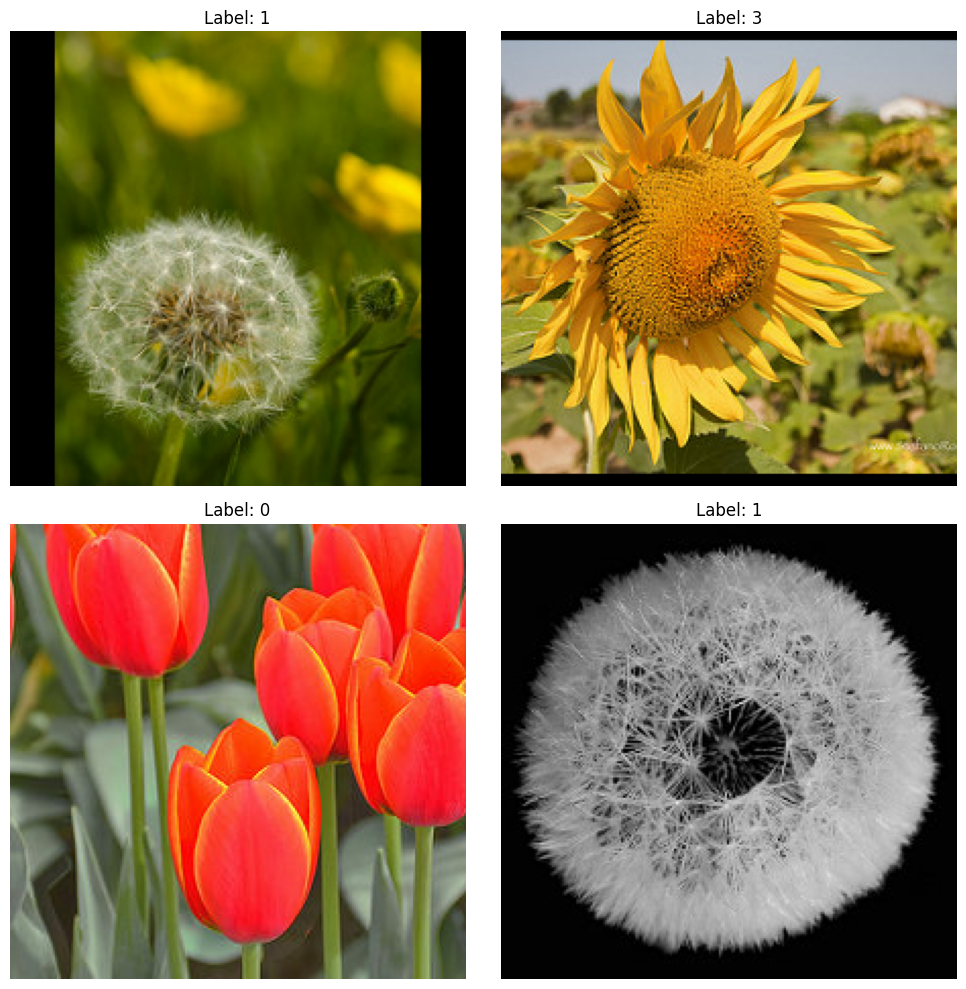

In [ ]:
for images, labels in train_ds.take(1):
  images_numpy = images.numpy()

  # 1. Check the pixel value range (Min and Max)
  print("--- Pixel Value Analysis ---")
  print("Minimum pixel value in this batch:", np.min(images_numpy))
  print("Maximum pixel value in this batch:", np.max(images_numpy))
  print("Data type:", images_numpy.dtype)
  print("----------------------------\n")

  plt.figure(figsize=(10, 10))
  for i in range(min(4, images_numpy.shape[0])):
      plt.subplot(2, 2, i + 1)

      img_to_show = images_numpy[i]
      if np.min(images_numpy) < 0:
        img_to_show = (img_to_show + 1.0) / 2.0

      img_to_show = np.clip(img_to_show, 0, 1 if img_to_show.dtype.kind == 'f' else 255)

      plt.imshow(img_to_show)
      plt.title(rel_label := f"Label: {labels[i].numpy()}")
      plt.axis("off")

  plt.tight_layout()
  plt.show()

  ## Hyperparameter Tuning

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

In [ ]:
# Run this just to get best hyperparameter
tuner = kt.BayesianOptimization(
    hypermodel=build_model,
    objective='val_loss',
    max_trials=30,
    executions_per_trial=1,
    directory=f"{PROJECT_DIR}/global_tuning_results",
    project_name=MODEL_FILE_NAME,
    overwrite=False
)

Reloading Tuner from /content/drive/MyDrive/FDL Project/global_tuning_results/SCRATCH_v12.0/tuner0.json


In [ ]:
val_fold_idx = 0
train_df = df_main[df_main['fold'] != val_fold_idx]
train_labels = train_df['label'].values

unique_classes = np.unique(train_labels)
weights = compute_class_weight(
    class_weight='balanced',
    classes=unique_classes,
    y=train_labels
)
class_weight_dict = {int(cls): float(w) for cls, w in zip(unique_classes, weights)}

train_ds, val_ds,_ , _ = load_common_datasets(
    project_dir=PROJECT_DIR,
    val_fold=0,
    img_size=224,
    batch_size=32,
    normalization="rescale_m1_1",
    train_file_name="train_folds_v2_distributed.csv"
)

tuner = kt.BayesianOptimization(
    hypermodel=build_model,
    objective='val_loss',
    max_trials=30,
    executions_per_trial=1,
    directory=f"{PROJECT_DIR}/global_tuning_results",
    project_name=MODEL_FILE_NAME,
    overwrite=False
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    min_delta=0.005,
    patience=7,
    restore_best_weights=True,
    verbose=1
)

tuner.search(
    train_ds,
    validation_data=val_ds,
    epochs=100,
    class_weight=class_weight_dict,
    callbacks=[reduce_lr, early_stopping],
    verbose=1
)


Trial 17 Complete [00h 02m 01s]
val_loss: 0.7122337222099304

Best val_loss So Far: 0.4810638427734375
Total elapsed time: 00h 49m 18s

Search: Running Trial #18

Value             |Best Value So Far |Hyperparameter
128               |64                |first_conv_filters
0.0001            |0.001             |learning_rate
elu               |relu              |activation_func
4                 |4                 |num_blocks
64                |256               |hp_dense_units
0.3               |0.2               |dropout_rate
0.0001            |0.0001            |l2_reg

Epoch 1/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 29s 252ms/step - accuracy: 0.5047 - loss: 1.2956 - val_accuracy: 0.2553 - val_loss: 1.8597 - learning_rate: 1.0000e-04
Epoch 2/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.5699 - loss: 1.1103 - val_accuracy: 0.2730 - val_loss: 1.9427 - learning_rate: 1.0000e-04
Epoch 3/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 5s 67ms/step - accuracy: 0.5961 - loss: 1.0591 - val_accuracy: 0.3369

KeyboardInterrupt: 

In [ ]:
# RESULTS
tuner.results_summary()

Results summary
Results in /content/drive/MyDrive/FDL Project/global_tuning_results/SCRATCH_v12.0
Showing 10 best trials
Objective(name="val_loss", direction="min")

Trial 09 summary
Hyperparameters:
first_conv_filters: 64
learning_rate: 0.001
activation_func: relu
num_blocks: 4
hp_dense_units: 256
dropout_rate: 0.2
l2_reg: 0.0001
Score: 0.4810638427734375

Trial 08 summary
Hyperparameters:
first_conv_filters: 64
learning_rate: 0.001
activation_func: relu
num_blocks: 4
hp_dense_units: 64
dropout_rate: 0.4
l2_reg: 0.001
Score: 0.5272487998008728

Trial 02 summary
Hyperparameters:
first_conv_filters: 128
learning_rate: 0.0003
activation_func: leaky_relu
num_blocks: 3
hp_dense_units: 128
dropout_rate: 0.2
l2_reg: 0.0001
Score: 0.5605868101119995

Trial 06 summary
Hyperparameters:
first_conv_filters: 128
learning_rate: 0.0003
activation_func: leaky_relu
num_blocks: 3
hp_dense_units: 512
dropout_rate: 0.30000000000000004
l2_reg: 0.0001
Score: 0.5655868649482727

Trial 04 summary
Hyperparame

In [ ]:
best_hps_list = tuner.get_best_hyperparameters(num_trials=5)

print("\n--- Top 5 Optimal Hyperparameters Found ---")

for i, best_hps in enumerate(best_hps_list):
    print(f"\nRank {i+1}:")
    for param in best_hps.values:
        print(f"  {param}: {best_hps.get(param)}")

winning_hps = best_hps_list[0]
print("\n--- Chosen Hyperparameters ---")
print(winning_hps.values)


--- Top 5 Optimal Hyperparameters Found ---

Rank 1:
  first_conv_filters: 64
  learning_rate: 0.001
  activation_func: relu
  num_blocks: 4
  hp_dense_units: 256
  dropout_rate: 0.2
  l2_reg: 0.0001

Rank 2:
  first_conv_filters: 64
  learning_rate: 0.001
  activation_func: relu
  num_blocks: 4
  hp_dense_units: 64
  dropout_rate: 0.4
  l2_reg: 0.001

Rank 3:
  first_conv_filters: 128
  learning_rate: 0.0003
  activation_func: leaky_relu
  num_blocks: 3
  hp_dense_units: 128
  dropout_rate: 0.2
  l2_reg: 0.0001

Rank 4:
  first_conv_filters: 128
  learning_rate: 0.0003
  activation_func: leaky_relu
  num_blocks: 3
  hp_dense_units: 512
  dropout_rate: 0.30000000000000004
  l2_reg: 0.0001

Rank 5:
  first_conv_filters: 32
  learning_rate: 0.001
  activation_func: elu
  num_blocks: 4
  hp_dense_units: 128
  dropout_rate: 0.30000000000000004
  l2_reg: 0.0001

--- Chosen Hyperparameters ---
{'first_conv_filters': 64, 'learning_rate': 0.001, 'activation_func': 'relu', 'num_blocks': 4, 'hp

## Define Save Model Function

In [ ]:
def save_model(model, current_fold):
  model_name = f"{MODEL_FILE_NAME}_fold_{current_fold}_{CURRENT_DATE}.keras"
  save_path = os.path.join(MODEL_DIR, model_name)

  model.save(save_path)
  print(f"Saved model to: {save_path}")

## Model Training w/ Cross Validation

In [ ]:
EPOCHS = 100

In [ ]:
print(winning_hps.values)

{'first_conv_filters': 64, 'learning_rate': 0.001, 'activation_func': 'relu', 'num_blocks': 4, 'hp_dense_units': 256, 'dropout_rate': 0.2, 'l2_reg': 0.0001}


In [ ]:
all_fold_histories = []
NUM_FOLDS = 5
for current_fold in unique_folds:
  print(f"========== TRAINING FOLD {current_fold + 1} / {NUM_FOLDS} ==========")

  train_df = df_main[df_main['fold'] != current_fold]
  train_labels = train_df['label'].values

  unique_classes = np.unique(train_labels)
  weights = compute_class_weight(
      class_weight='balanced',
      classes=unique_classes,
      y=train_labels
  )
  class_weight_dict = {int(cls): float(w) for cls, w in zip(unique_classes, weights)}

  # PREPARE TRAIN AND VAL DATA HERE
  train_ds, val_ds,_ , _ = load_common_datasets(
    project_dir=PROJECT_DIR,
    val_fold=current_fold,
    img_size=224,
    batch_size=32,
    normalization="rescale_m1_1",
    train_file_name="train_folds_v3.csv"
  )

  # DEFINE MODEL
  model = initialize_model(
    input_shape=(224, 224, 3),
    num_classes=5,
    augmentation_pipeline=None,
    **winning_hps.values
  )

  reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
  )

  # DEFINE EARLY STOPPING
  early_stopping = EarlyStopping(
    monitor='val_loss',
    min_delta=0.005,
    patience=7,
    restore_best_weights=True,
    verbose=1
  )

  # TRAIN MODEL
  history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weight_dict,
    callbacks=[reduce_lr, early_stopping]
  )

  # SAVE HISTORY
  all_fold_histories.append(history.history)

  # SAVE MODEL
  save_model(model, current_fold)

========== TRAINING FOLD 1 / 5 ==========
Epoch 1/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 208s 727ms/step - accuracy: 0.5007 - loss: 1.2519 - val_accuracy: 0.3138 - val_loss: 2.0206 - learning_rate: 0.0010
Epoch 2/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.6178 - loss: 1.0270 - val_accuracy: 0.2926 - val_loss: 2.6599 - learning_rate: 0.0010
Epoch 3/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.6485 - loss: 0.9615 - val_accuracy: 0.4131 - val_loss: 2.2255 - learning_rate: 0.0010
Epoch 4/100
69/71 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.6717 - loss: 0.8789
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.6826 - loss: 0.8714 - val_accuracy: 0.3067 - val_loss: 2.0495 - learning_rate: 0.0010
Epoch 5/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.6973 - loss: 0.8106 - val_accuracy: 0.4486 - val_loss: 1.6516 - learning_rate: 5.0000e-04
Epoch 6/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s

## Save Results

In [ ]:
def plot_cv_results(all_fold_histories):
    epochs_trained = len(all_fold_histories[0]['loss'])
    epochs_range = range(1, epochs_trained + 1)

    plt.figure(figsize=(14, 5))

    # PLOT 1: ACCURACY
    plt.subplot(1, 2, 1)
    for i, history in enumerate(all_fold_histories):
        plt.plot(history['accuracy'], label=f'Train Fold {i}', linestyle='--')
        plt.plot(history['val_accuracy'], label=f'Val Fold {i}', linewidth=2)
    plt.title('Training and Validation Accuracy across Folds')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')
    plt.grid(True, alpha=0.3)

    # PLOT 2: LOSS
    plt.subplot(1, 2, 2)
    for i, history in enumerate(all_fold_histories):
        plt.plot(history['loss'], label=f'Train Fold {i}', linestyle='--')
        plt.plot(history['val_loss'], label=f'Val Fold {i}', linewidth=2)
    plt.title('Training and Validation Loss across Folds')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(f"{PLOT_DIR}/{MODEL_FILE_NAME}.png", dpi=300, bbox_inches='tight')
    plt.show()

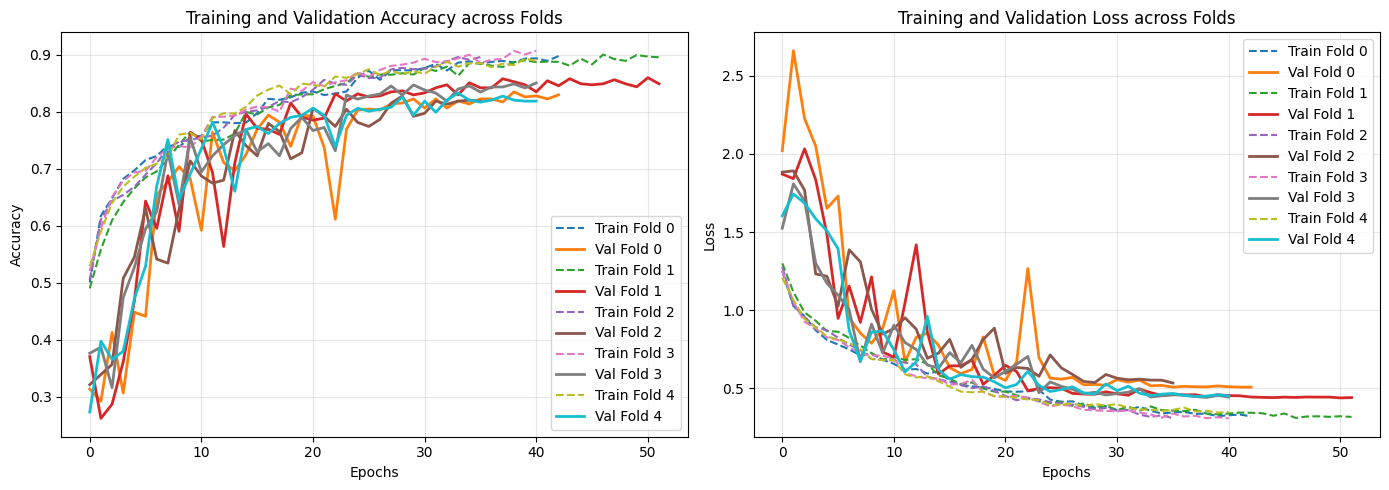

In [ ]:
plot_cv_results(all_fold_histories)

In [ ]:
def save_cv_history(all_fold_histories, filepath):
    def native_convert(obj):
        if isinstance(obj, np.ndarray):
            return obj.tolist()
        if isinstance(obj, (np.float32, np.float64)):
            return float(obj)
        if isinstance(obj, (np.int32, np.int64)):
            return int(obj)
        raise TypeError(f"Object of type {type(obj)} is not JSON serializable")

    with open(filepath, 'w') as f:
        json.dump(all_fold_histories, f, default=native_convert, indent=4)
    print(f"History successfully saved to {filepath}")

In [ ]:
save_cv_history(all_fold_histories, f"{HISTORY_DIR}/{MODEL_FILE_NAME}_history.json")

History successfully saved to /content/drive/MyDrive/FDL Project/history/SCRATCH_v13.0_history.json
